**Question 1**

I would choose the first-order difference(b) of the Bitcoin closing price.

The original Bitcoin price changes a lot over time and shows a clear trend. This means the price series may not be stationary, because its mean changes over time. A time series model usually works better when the data is stationary.

The first-order difference is calculated by subtracting the previous day's closing price from the current day's closing price. It shows how much the price changes each day, rather than the price itself. This can help reduce the trend and make the series more stationary.

Therefore, I would choose the first-order difference.

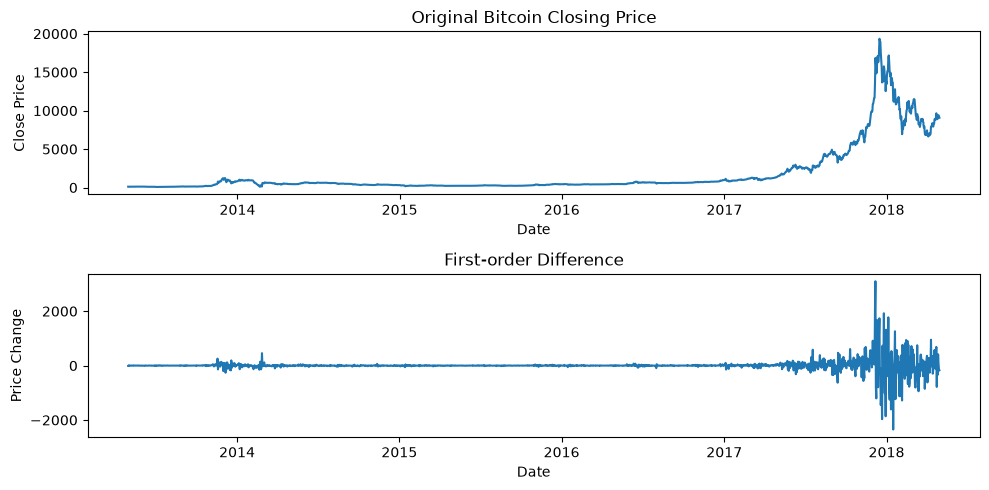

ADF test for original price:
ADF Statistic: -1.4634379867213083
p-value: 0.5515

ADF test for first-order difference:
ADF Statistic: -7.042378868963039
p-value: 0.0000000006


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Read the data
data = pd.read_csv('../data/Q5BTC-USD.csv')
data['Date'] = pd.to_datetime(data['Date'])
data = data.sort_values('Date')

# Original price
close = data['Close']
# First-order difference
diff_close = close.diff().dropna()

# Plot the original price and first-order difference
plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1)
plt.plot(data['Date'], close)
plt.title('Original Bitcoin Closing Price')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.subplot(2, 1, 2)
plt.plot(data['Date'].iloc[1:], diff_close)
plt.title('First-order Difference')
plt.xlabel('Date')
plt.ylabel('Price Change')
plt.tight_layout()
plt.show()

# ADF test for the original price
result1 = adfuller(close)
print('ADF test for original price:')
print('ADF Statistic:', result1[0])
print('p-value:', round(result1[1], 4))

# ADF test for the first-order difference
result2 = adfuller(diff_close)
print('\nADF test for first-order difference:')
print('ADF Statistic:', result2[0])
print('p-value:', '{:.10f}'.format(result2[1]))

To support my choice, I plotted the closing prices and their first differences to compare them. The closing prices show an overall upward trend, while the first differences move up and down around zero.

I also ran an ADF test to check stationarity. For the raw closing prices, the p-value was about 0.55, which is above 0.05, so I cannot reject the null hypothesis of a unit root. For the first differences, the p-value was less than 0.001, which is below 0.05, so I can reject the null hypothesis. This suggests that the first differences are stationary. Therefore, I would choose (D_Close_t) as the dependent variable instead of (Close_t).

**Question 2**

        Date   Actual  Forecast
0 2018-04-26  8938.47   9282.08
1 2018-04-27  9351.47   9282.08
2 2018-04-28  9407.04   9282.08
3 2018-04-29  9248.45   9282.08
4 2018-04-30  9077.28   9282.08
RMSE: 190.56293957359478


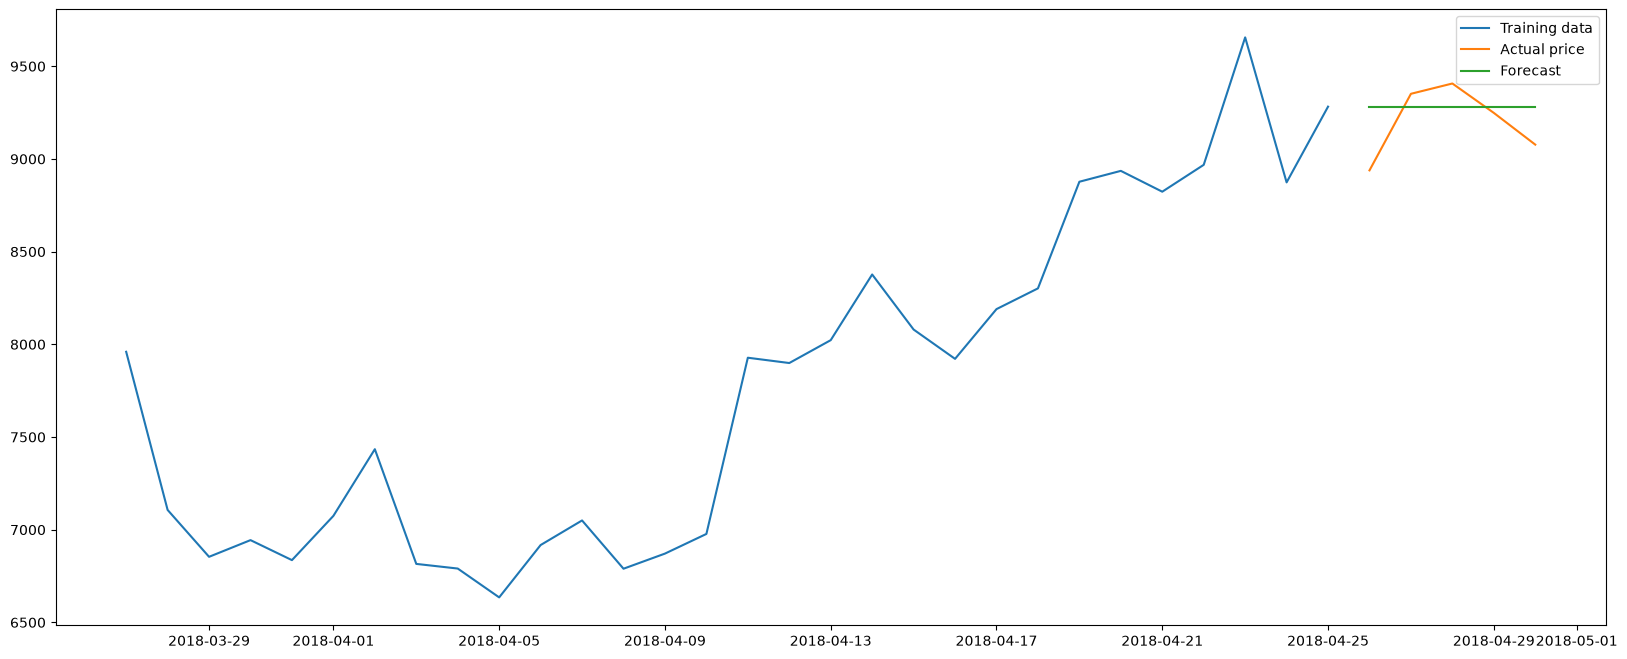

In [2]:
import pandas as pd
import numpy as np
from sklearn import metrics
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from matplotlib import pyplot as plt

btc = pd.read_csv('../data/Q5BTC-USD.csv')
btc['Date'] = pd.to_datetime(btc['Date'])
btc = btc.sort_values('Date').reset_index(drop=True)
btc_train = btc.iloc[:-5]
btc_test = btc.iloc[-5:]
y_train = btc_train['Close']
y_test = btc_test['Close']

# basic ETS model
model = ETSModel(y_train)
fit = model.fit()
y_predict = fit.forecast(5)

# forecast the next five days
rmse = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=y_test))
result = pd.DataFrame({'Date': btc_test['Date'].values, 'Actual': y_test.values, 'Forecast': y_predict.values})
result['Actual'] = result['Actual'].round(2)
result['Forecast'] = result['Forecast'].round(2)
print(result)
print('RMSE:', rmse)

plt.figure(figsize=(20, 8))
plt.plot(btc_train['Date'].tail(30), btc_train['Close'].tail(30), label='Training data')
plt.plot(btc_test['Date'], y_test, label='Actual price')
plt.plot(btc_test['Date'], y_predict.values, label='Forecast')
plt.legend()
plt.show()

In this question, I used the ETS model without trend and seasonality to forecast the Bitcoin closing prices for the last five days. The RMSE was 190.56.

As the result in the table, the predicted values are all the same (9282.08). This is because the model does not include a trend or seasonality component. It mainly uses the level of the time series to make predictions, so the forecast stays constant for all five days.

Overall, the model gives a simple forecast, but it cannot capture the daily price changes of Bitcoin very well.

**Question 3**

Q2: Basic ETS
        Date   Actual     Forecast
0 2018-04-26  8938.47  9282.079158
1 2018-04-27  9351.47  9282.079158
2 2018-04-28  9407.04  9282.079158
3 2018-04-29  9248.45  9282.079158
4 2018-04-30  9077.28  9282.079158
RMSE: 190.56



Q3: ETS with trend
        Date   Actual     Forecast
0 2018-04-26  8938.47  9287.112834
1 2018-04-27  9351.47  9292.146011
2 2018-04-28  9407.04  9297.179187
3 2018-04-29  9248.45  9302.212364
4 2018-04-30  9077.28  9307.245541
RMSE: 196.43

Model comparison
Basic ETS RMSE: 190.56
ETS with trend RMSE: 196.43


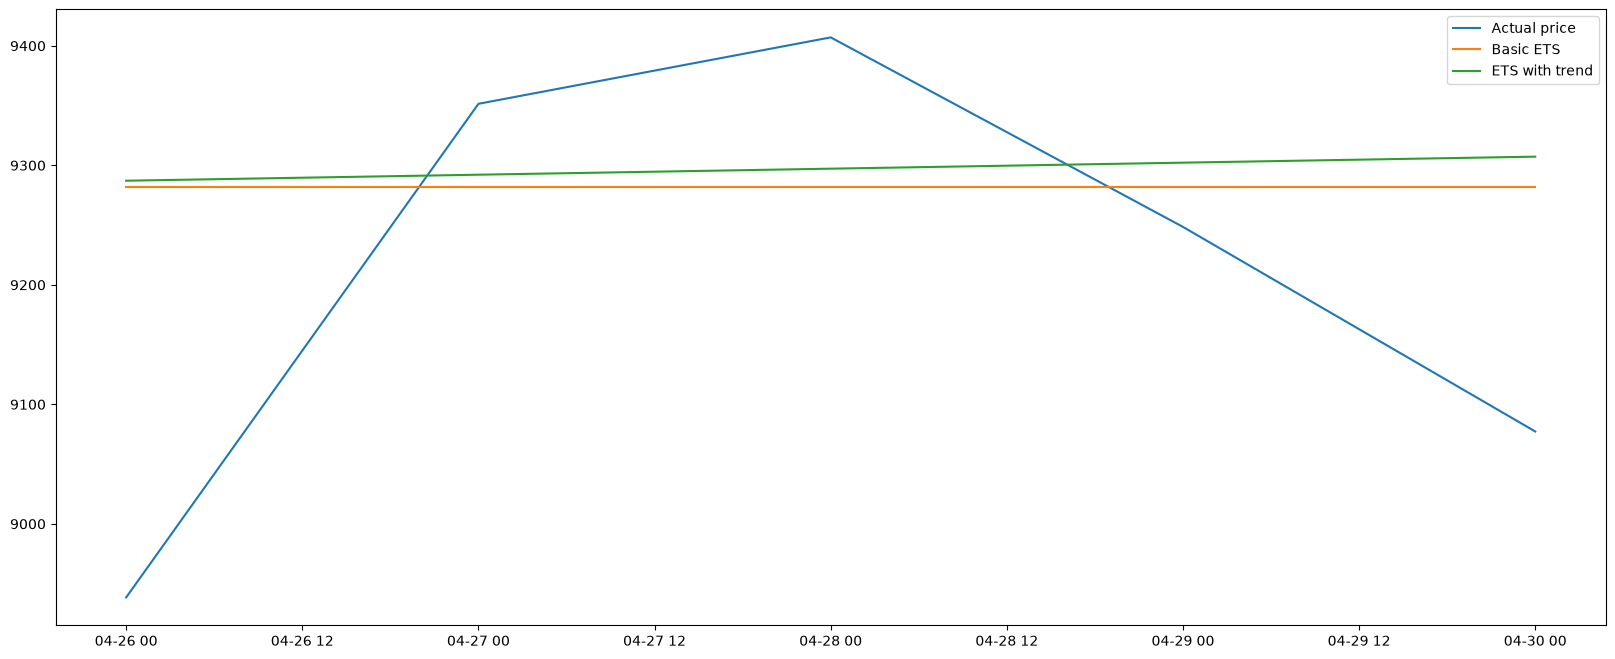

In [3]:
# Q2: basic ETS model
model_basic = ETSModel(y_train)
fit_basic = model_basic.fit()
y_predict_basic = fit_basic.forecast(5)
rmse_basic = np.sqrt(metrics.mean_squared_error(y_pred=y_predict_basic, y_true=y_test))

print('Q2: Basic ETS')
print(pd.DataFrame({'Date': btc_test['Date'].values, 'Actual': y_test.values,'Forecast': y_predict_basic.values}))
print('RMSE:', round(rmse_basic,2))

# Q3: ETS model with trend
model_trend = ETSModel(y_train, trend='add')
fit_trend = model_trend.fit()
y_predict_trend = fit_trend.forecast(5)
rmse_trend = np.sqrt(metrics.mean_squared_error(y_pred=y_predict_trend, y_true=y_test))

print('\nQ3: ETS with trend')
print(pd.DataFrame({'Date': btc_test['Date'].values, 'Actual': y_test.values, 'Forecast': y_predict_trend.values}))
print('RMSE:', round(rmse_trend,2))

# compare the two models
print('\nModel comparison')
print('Basic ETS RMSE:', round(rmse_basic,2))
print('ETS with trend RMSE:', round(rmse_trend,2))

# plot the results
plt.figure(figsize=(20, 8))
plt.plot(btc_test['Date'], y_test, label='Actual price')
plt.plot(btc_test['Date'], y_predict_basic.values, label='Basic ETS')
plt.plot(btc_test['Date'], y_predict_trend.values, label='ETS with trend')
plt.legend()
plt.show()

In this question, I added a trend component to the ETS model and compared it with the basic ETS model in Q2.

Unlike the basic ETS model given the same forecast for all five days, the model with trend gives different forecast values for each day. The forecast increases from 9287.11 to 9307.25 because the model considers the trend in the data.

The basic ETS model has an RMSE of 190.56 and the ETS model with trend has an RMSE of 196.45. AS the result, the RMSE of the model which is slightly higher than the basic ETS model's RMSE. This means that adding a trend does not improve the forecasting accuracy in this case.

This shows that adding a trend component does not always improve forecasting accuracy. For this dataset and test period, the basic ETS model is more suitable because its prediction errors are smaller.

**Question 4**

I would use rolling forecasting to compare the next-day prediction performance of the two models.

First, I would sort the Bitcoin data by date and use the first 80% of the data for training. The remaining 20% would be used for testing.

For each day in the test period, I would fit the model using all the data available up to that point and predict the next day's closing price. I would then calculate the prediction error, add the actual closing price to the training data, and move on to the next day. I would repeat this until the end of the test period, so the model only uses data that would have been available at the time.

I would use RMSE as the main metric and MAE as a second metric. RMSE measures the square root of the average squared prediction errors, while MAE measures the average absolute errors. Both are measured in dollars, and lower values indicate better predictions.

Finally, I would compare the Basic ETS model and the ETS model with trend using the same test period. The model with lower RMSE and MAE would be considered better for this dataset. Testing the models over multiple days should also give a clearer picture of their performance than using only five observations.